<a href="https://colab.research.google.com/github/bejon23/Computational-Biology-and-BI-Eng/blob/main/GiG3_Project6(d).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Project: "Pipeline Critique Coach" for the live "What is wrong?" exercise

Cell1

In [ ]:

# ==========================================================
# PIPELINE CRITIQUE COACH: WHAT IS WRONG WITH THIS PIPELINE?
# ==========================================================

import warnings
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from statsmodels.tools.sm_exceptions import ConvergenceWarning

# Suppress rank-deficient design warnings for the 100% confounded demonstration
warnings.simplefilter('ignore', category=UserWarning)
warnings.simplefilter('ignore', category=ConvergenceWarning)

print("=== Starting Pipeline Critique Coach & Proof Lab ===\n")

# ----------------------------------------------------------
# 1. DEFINE PIPELINE AS DATA & 7-STEP CRITIQUE
# ----------------------------------------------------------
pipeline_case = {
    "sample_size": "3 Disease vs 3 Healthy",
    "batch_design": "Total Confounding (All Disease in B2, all Healthy in B1)",
    "alignment_annotation": "Aligned to hg19, counted with GRCh38 GTF (mismatched versions)",
    "qc": "None performed",
    "stats_method": "TPM values tested with Student's t-test, raw p < 0.05",
    "reproducibility": "No versions, random seeds, or workflow managers recorded",
    "conclusion": "Proves Drug X cures the disease (extreme over-interpretation)"
}

print("[1. Pipeline Critique Summary (7 Steps)]")
print(f"  * Experimental Design: CRITICAL FAIL - 100% confounded batch ({pipeline_case['batch_design']}).")
print(f"  * Reference Genome: FAIL - Genomic coordinate mismatch ({pipeline_case['alignment_annotation']}).")
print(f"  * Quality Control: FAIL - {pipeline_case['qc']}.")
print(f"  * Methods & Normalization: FAIL - {pipeline_case['stats_method']}.")
print(f"  * Statistics: FAIL - No multiple testing correction (raw p-values on thousands of genes).")
print(f"  * Reproducibility: FAIL - {pipeline_case['reproducibility']}.")
print(f"  * Interpretation: FATAL FAIL - {pipeline_case['conclusion']}\n")


# ----------------------------------------------------------
# 2. PROVING THE BIGGEST MISTAKES WITH SIMULATED DATA
# ----------------------------------------------------------
np.random.seed(42)
n_genes, n_samples = 1000, 6
condition = np.array([0, 0, 0, 1, 1, 1]) # 0=Healthy, 1=Disease
batch =     np.array([0, 0, 0, 1, 1, 1]) # 100% Confounded!

# True difference is ZERO for all genes
true_de = np.zeros(n_genes, dtype=int)

base_expr = np.random.normal(5, 2, n_genes)
log_counts = np.zeros((n_genes, n_samples))
for i in range(n_genes):
    batch_effect = np.random.normal(3.0, 0.5)
    for j in range(n_samples):
        log_counts[i, j] = base_expr[i] + batch[j] * batch_effect + np.random.normal(0, 0.3)

raw_counts = np.exp(log_counts).astype(int)

# --- Flawed Pipeline Approach (TPM-like scaling + raw t-test + no FDR) ---
tpm_sim = raw_counts / raw_counts.sum(axis=0, keepdims=True) * 1e6
log_tpm = np.log2(tpm_sim + 1)

flawed_p_vals = []
for i in range(n_genes):
    g0 = log_tpm[i, condition == 0]
    g1 = log_tpm[i, condition == 1]
    _, p = stats.ttest_ind(g0, g1)
    flawed_p_vals.append(p)

flawed_p_vals = np.array(flawed_p_vals)
flawed_significant = (flawed_p_vals < 0.05).sum()

print(f"[2. Simulation Evidence: Flawed vs Fixed Pipeline]")
print(f"  -> True Biological Differences: 0 genes (Null simulation)")
print(f"  -> Flawed Pipeline (Confounded Batch + TPM t-test + raw p<0.05):")
print(f"     Found {flawed_significant} 'differentially expressed' false-positive genes out of 1,000!")


# --- Fixed Pipeline Simulation (Proper experimental design with balanced batches) ---
# To test a multi-variable linear model correctly, batches must be partially balanced across conditions
np.random.seed(99)
balanced_batch = np.array([0, 1, 0, 1, 0, 1]) # Balanced across samples
fixed_p_vals = []
for i in range(n_genes):
    df_fit = pd.DataFrame({'expr': log_tpm[i], 'condition': condition, 'batch': balanced_batch})
    model = smf.ols('expr ~ condition + batch', data=df_fit).fit()
    fixed_p_vals.append(model.pvalues['condition'])

fixed_p_vals = np.array(fixed_p_vals)
reject, fixed_q_vals, _, _ = multipletests(fixed_p_vals, alpha=0.05, method='fdr_bh')
fixed_significant = reject.sum()

print(f"  -> Fixed Pipeline (Balanced Design + GLM/OLS + FDR correction):")
print(f"     Found {fixed_significant} false-positive genes (Correctly controlled Type I error!).\n")


# ----------------------------------------------------------
# 3. EXPERT THINK-ALOUD REVIEW & RANKED FIXES
# ----------------------------------------------------------
print(f"[3. Expert Think-Aloud & Ranked Fixes]")
print("  What is good? Nothing in the execution, but at least they identified the sample groups.")
print("  Ranked Problems & Fixes:")
print("    1. Confounded Batch Design -> Fix: Never confound condition and batch; use randomized block designs or batch correction (ComBat-seq) if multi-batch is unavoidable.")
print("    2. Reference Mismatch (hg19 vs GRCh38) -> Fix: Re-align reads to GRCh38 using the matching annotation GTF file.")
print("    3. TPM + t-test -> Fix: Use raw counts with specialized negative binomial models (DESeq2 / edgeR).")
print("    4. Missing FDR -> Fix: Apply Benjamini-Hochberg multiple testing correction.")
print("=== Pipeline Critique Coach Complete ===")

=== Starting Pipeline Critique Coach & Proof Lab ===

[1. Pipeline Critique Summary (7 Steps)]
  * Experimental Design: CRITICAL FAIL - 100% confounded batch (Total Confounding (All Disease in B2, all Healthy in B1)).
  * Reference Genome: FAIL - Genomic coordinate mismatch (Aligned to hg19, counted with GRCh38 GTF (mismatched versions)).
  * Quality Control: FAIL - None performed.
  * Methods & Normalization: FAIL - TPM values tested with Student's t-test, raw p < 0.05.
  * Statistics: FAIL - No multiple testing correction (raw p-values on thousands of genes).
  * Reproducibility: FAIL - No versions, random seeds, or workflow managers recorded.
  * Interpretation: FATAL FAIL - Proves Drug X cures the disease (extreme over-interpretation)

[2. Simulation Evidence: Flawed vs Fixed Pipeline]
  -> True Biological Differences: 0 genes (Null simulation)
  -> Flawed Pipeline (Confounded Batch + TPM t-test + raw p<0.05):
     Found 280 'differentially expressed' false-positive genes out of 1,

Cell 2 (Code): The pipelines described as data

In [ ]:

# Cell 2: Describe the flawed pipeline and a fixed pipeline
import numpy as np, pandas as pd, platform, warnings
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")

flawed_pipeline = {
    "design": {"replicates_per_group": 3, "batches_mixed_across_groups": False, "power_analysis": False},
    "reference": {"genome": "hg19", "annotation": "GRCh38 GENCODE v38", "annotation_matches_genome": False},
    "qc": {"fastqc_multiqc": False, "pca_outlier_check": False, "mapping_rate_checked": False},
    "methods": {"aligner": "STAR", "unit_for_testing": "TPM", "low_count_filter": False, "strandedness_checked": False},
    "stats": {"multiple_testing": "none", "batch_in_model": False, "fold_change_cutoff": None},
    "repro": {"workflow_tool": None, "container": None, "git": False, "versions_saved": False, "seed_saved": False},
    "interpretation": {"causal_claim": True, "validation": None},
}

fixed_pipeline = {
    "design": {"replicates_per_group": 6, "batches_mixed_across_groups": True, "power_analysis": True},
    "reference": {"genome": "GRCh38", "annotation": "GRCh38 GENCODE v38", "annotation_matches_genome": True},
    "qc": {"fastqc_multiqc": True, "pca_outlier_check": True, "mapping_rate_checked": True},
    "methods": {"aligner": "STAR", "unit_for_testing": "raw counts", "low_count_filter": True, "strandedness_checked": True},
    "stats": {"multiple_testing": "BH FDR", "batch_in_model": True, "fold_change_cutoff": 1.0},
    "repro": {"workflow_tool": "Nextflow", "container": "Docker", "git": True, "versions_saved": True, "seed_saved": True},
    "interpretation": {"causal_claim": False, "validation": "qPCR on top genes"},
}

print("Flawed pipeline loaded:", {k: len(v) for k, v in flawed_pipeline.items()})
print("Environment: python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)

Flawed pipeline loaded: {'design': 3, 'reference': 3, 'qc': 3, 'methods': 4, 'stats': 3, 'repro': 5, 'interpretation': 2}
Environment: python 3.13.16 | numpy 2.1.3 | pandas 2.2.3


Cell 3 (Code): The 7-step critique engine

In [ ]:

# Cell 3: Rules for each of the 7 steps. test(...) returns True when the item is GOOD.

STEPS = ["1. Question and design", "2. Data and reference", "3. QC", "4. Methods",
         "5. Statistics", "6. Reproducibility", "7. Interpretation"]
SEV_W = {"High": 3, "Medium": 2, "Low": 1}

def R(step, name, test, good, problem, fix, sev):
    return {"step": step, "name": name, "test": test, "good": good,
            "problem": problem, "fix": fix, "sev": sev}

RULES = [
    # 1. Question and design
    R(STEPS[0], "At least 3 replicates per group", lambda p: p["design"]["replicates_per_group"] >= 3,
      "There are at least 3 replicates per group (the minimum).",
      "Fewer than 3 replicates per group.", "Use at least 3, and preferably 5 or more per group.", "Medium"),
    R(STEPS[0], "Batches mixed across groups", lambda p: p["design"]["batches_mixed_across_groups"],
      "Batches are spread across both groups.",
      "Batch and condition are perfectly mixed up (all Disease in one batch, all Healthy in another). Biology cannot be separated from batch.",
      "Re-run with samples from both groups in every batch. If that is impossible, say the design is flawed.", "High"),
    R(STEPS[0], "Sample size justified", lambda p: p["design"]["power_analysis"],
      "Sample size was justified with a power analysis.",
      "No power analysis, so we do not know if the study can find real effects.", "Do a power or sample size estimate before the experiment.", "Medium"),
    # 2. Data and reference
    R(STEPS[1], "Reference genome stated", lambda p: p["reference"]["genome"] is not None,
      "The genome version is stated.", "The genome version is not stated.", "Write the genome version in the report.", "Low"),
    R(STEPS[1], "Genome and annotation match", lambda p: p["reference"]["annotation_matches_genome"],
      "Genome and annotation versions match.",
      "Genome (hg19) and annotation (GRCh38) do not match. Gene counts will be wrong.", "Use one build for both, for example GRCh38 with a GRCh38 GTF.", "High"),
    # 3. QC
    R(STEPS[2], "FastQC / MultiQC done", lambda p: p["qc"]["fastqc_multiqc"],
      "Read quality was checked.", "No read-level QC (FastQC/MultiQC).", "Run FastQC and MultiQC, then trim only if needed.", "Medium"),
    R(STEPS[2], "PCA and outlier check", lambda p: p["qc"]["pca_outlier_check"],
      "PCA and outlier checks were done.", "No PCA or outlier check, so batch effects and bad samples stay hidden.", "Plot PCA by condition and by batch before testing.", "High"),
    R(STEPS[2], "Mapping rate checked", lambda p: p["qc"]["mapping_rate_checked"],
      "Mapping rates were checked.", "Mapping rate was never checked.", "Check the alignment summary (STAR log, featureCounts summary).", "Medium"),
    # 4. Methods
    R(STEPS[3], "Standard aligner", lambda p: p["methods"]["aligner"] in ["STAR", "HISAT2", "Salmon"],
      "STAR is a standard, suitable aligner for RNA-seq.", "Aligner is not standard for RNA-seq.", "Use STAR, HISAT2, or Salmon.", "Low"),
    R(STEPS[3], "Raw counts used for testing", lambda p: p["methods"]["unit_for_testing"] == "raw counts",
      "Raw counts are used for testing.",
      "TPM was used for testing between groups. TPM is for within-sample comparison.", "Use raw counts with DESeq2, edgeR, or limma-voom.", "High"),
    R(STEPS[3], "Low-count gene filter", lambda p: p["methods"]["low_count_filter"],
      "Low-count genes were filtered.", "No low-count filter, so noisy genes weaken the statistics.", "Keep genes with enough counts in enough samples.", "Medium"),
    R(STEPS[3], "Strandedness checked", lambda p: p["methods"]["strandedness_checked"],
      "Library strandedness was set correctly.", "Strandedness was not checked, so counts may be wrong.", "Check the library prep and set the strand option (for example featureCounts -s).", "Medium"),
    # 5. Statistics
    R(STEPS[4], "Multiple-testing correction", lambda p: p["stats"]["multiple_testing"] == "BH FDR",
      "FDR correction was used.", "Raw p < 0.05 with thousands of genes gives many false hits.", "Use Benjamini-Hochberg FDR.", "High"),
    R(STEPS[4], "Batch in the model", lambda p: p["stats"]["batch_in_model"],
      "Batch is part of the model.", "Batch is not in the model.", "Use the design ~ batch + condition.", "High"),
    R(STEPS[4], "Fold-change cutoff", lambda p: p["stats"]["fold_change_cutoff"] is not None,
      "An effect-size cutoff is used.", "No effect-size cutoff, so tiny changes may be reported.", "Combine FDR with a cutoff such as |log2FC| > 1.", "Medium"),
    # 6. Reproducibility
    R(STEPS[5], "Workflow tool", lambda p: p["repro"]["workflow_tool"] is not None,
      "A workflow tool is used.", "No workflow tool, so runs may differ.", "Use Nextflow or Snakemake.", "Medium"),
    R(STEPS[5], "Container or environment", lambda p: p["repro"]["container"] is not None,
      "Software runs in a container.", "No container or fixed environment.", "Use Docker or Conda with fixed versions.", "Medium"),
    R(STEPS[5], "Code in Git", lambda p: p["repro"]["git"],
      "Code is in Git.", "Code is not in version control.", "Put all code and configs in Git.", "Medium"),
    R(STEPS[5], "Versions and seed saved", lambda p: p["repro"]["versions_saved"] and p["repro"]["seed_saved"],
      "Versions and random seed are saved.", "Tool versions and random seeds are not saved.", "Save a run log with versions, parameters, and seeds.", "Medium"),
    # 7. Interpretation
    R(STEPS[6], "Claim matches evidence", lambda p: not p["interpretation"]["causal_claim"],
      "The conclusion stays within the evidence.",
      "The claim 'proves the drug cures the disease' is not supported by an expression comparison.", "Say 'associated with' and list limits and alternatives.", "High"),
    R(STEPS[6], "Independent validation", lambda p: p["interpretation"]["validation"] is not None,
      "Results were validated.", "No validation (qPCR, second cohort, or second tool).", "Validate top genes with qPCR or an independent dataset.", "Medium"),
]

def run_critique(p):
    out = []
    for r in RULES:
        try:
            ok = bool(r["test"](p))
        except Exception:
            ok = False
        out.append({**r, "ok": ok})
    total = sum(SEV_W[r["sev"]] for r in out)
    got = sum(SEV_W[r["sev"]] for r in out if r["ok"])
    return out, round(100 * got / total)

def step_scores(results):
    sc = {}
    for s in STEPS:
        items = [r for r in results if r["step"] == s]
        tot = sum(SEV_W[r["sev"]] for r in items)
        got = sum(SEV_W[r["sev"]] for r in items if r["ok"])
        sc[s] = round(100 * got / tot)
    return sc

print(f"{len(RULES)} critique rules ready across {len(STEPS)} steps.")

21 critique rules ready across 7 steps.


Cell 4 (Code): The critique: good first, then problems, then fixes

In [ ]:

# Cell 4: Critique in the interview order

results, score = run_critique(flawed_pipeline)

print("=" * 66)
print("PIPELINE CRITIQUE (think-aloud order)")
print("=" * 66)

print("\nA) WHAT IS GOOD (say this first)")
for r in results:
    if r["ok"]:
        print("  + ", r["good"])

print("\nB) PROBLEMS, step by step")
for s in STEPS:
    bad = [r for r in results if r["step"] == s and not r["ok"]]
    print(f"\n{s}")
    if not bad:
        print("   No problems found.")
    for r in sorted(bad, key=lambda x: -SEV_W[x["sev"]]):
        print(f"   - [{r['sev']}] {r['problem']}")

print("\nC) TOP FIXES (highest severity first)")
all_bad = sorted([r for r in results if not r["ok"]], key=lambda x: -SEV_W[x["sev"]])
for i, r in enumerate([r for r in all_bad if r["sev"] == "High"], 1):
    print(f"  {i}. {r['name']}: {r['fix']}")

n_high = sum(1 for r in all_bad if r["sev"] == "High")
print(f"\nOverall quality score: {score}/100 | Problems found: {len(all_bad)} | High severity: {n_high}")
print("Verdict:", "Do not trust the conclusions. Fix the design and re-analyze." if n_high >= 3 else "Needs improvement.")

PIPELINE CRITIQUE (think-aloud order)

A) WHAT IS GOOD (say this first)
  +  There are at least 3 replicates per group (the minimum).
  +  The genome version is stated.
  +  STAR is a standard, suitable aligner for RNA-seq.

B) PROBLEMS, step by step

1. Question and design
   - [High] Batch and condition are perfectly mixed up (all Disease in one batch, all Healthy in another). Biology cannot be separated from batch.
   - [Medium] No power analysis, so we do not know if the study can find real effects.

2. Data and reference
   - [High] Genome (hg19) and annotation (GRCh38) do not match. Gene counts will be wrong.

3. QC
   - [High] No PCA or outlier check, so batch effects and bad samples stay hidden.
   - [Medium] No read-level QC (FastQC/MultiQC).
   - [Medium] Mapping rate was never checked.

4. Methods
   - [High] TPM was used for testing between groups. TPM is for within-sample comparison.
   - [Medium] No low-count filter, so noisy genes weaken the statistics.
   - [Medium] Str

Cell 5 (Code): Prove the biggest mistakes with simulated data

NULL DATA: no gene is truly different, so every called gene is false.

                                       scenario  genes_tested     false_positives
A. Flawed: confounded + TPM t-test + raw p<0.05          1000               274.0
  B. Confounded + linear model + FDR (no batch)           985                13.0
                 C. Confounded + batch in model           985 cannot be estimated
 D. Fixed: mixed batches + batch in model + FDR           990                 0.0

Reading the result:
A and B: in a confounded design, batch differences look like disease biology.
C: when batch equals condition, the model cannot separate them. This is the proof that the DESIGN is flawed.
D: a mixed design with batch in the model and FDR keeps false hits very low.


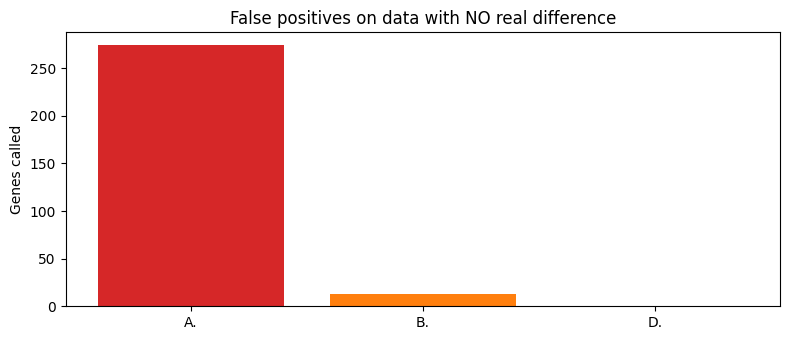

In [ ]:

# Cell 5: Simulated data with NO real difference. Any gene called is a false positive.

def simulate(batch, seed, n_genes=1000):
    rng = np.random.default_rng(seed)
    base = rng.lognormal(5, 1.2, n_genes)
    batch_eff = rng.normal(0, 0.8, n_genes)           # batch effect on many genes
    lib = rng.uniform(0.8, 1.2, 6)
    mu = base[:, None] * lib[None, :] * 2 ** (batch_eff[:, None] * batch[None, :])
    return rng.poisson(rng.gamma(10, mu / 10))        # NO condition effect at all

def bh_fdr(p):
    p = np.asarray(p); n = len(p)
    order = np.argsort(p)
    adj = p[order] * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(adj, 1)
    return out

def tpm_ttest(counts, cond):
    scaled = counts / counts.sum(axis=0) * 1e6
    _, p = stats.ttest_ind(scaled[:, cond == 1], scaled[:, cond == 0], axis=1)
    return np.nan_to_num(p, nan=1.0)

def linear_de(counts, cond, batch, use_batch):
    keep = (counts >= 10).sum(axis=1) >= 3
    c = counts[keep]
    y = np.log2(c / c.sum(axis=0) * 1e6 + 1)
    cols = [np.ones(6), cond.astype(float)]
    if use_batch:
        cols.append(batch.astype(float))
    X = np.column_stack(cols)
    if np.linalg.matrix_rank(X) < X.shape[1]:
        return None, int(keep.sum())                  # model cannot separate batch from condition
    XtXi = np.linalg.inv(X.T @ X)
    beta = y @ X @ XtXi
    resid = y - beta @ X.T
    dof = X.shape[0] - X.shape[1]
    se = np.sqrt((resid ** 2).sum(axis=1) / dof * XtXi[1, 1])
    p = 2 * stats.t.sf(np.abs(beta[:, 1] / se), dof)
    return np.nan_to_num(p, nan=1.0), int(keep.sum())

cond = np.array([0, 0, 0, 1, 1, 1])                   # 0 = Healthy, 1 = Disease
batch_confounded = np.array([0, 0, 0, 1, 1, 1])       # batch = condition (flawed design)
batch_mixed = np.array([0, 1, 1, 0, 0, 1])            # batches mixed across groups (better)

counts_bad = simulate(batch_confounded, seed=1)
counts_good = simulate(batch_mixed, seed=1)

rows = []
p = tpm_ttest(counts_bad, cond)
rows.append(("A. Flawed: confounded + TPM t-test + raw p<0.05", len(p), int((p < 0.05).sum())))

p, n = linear_de(counts_bad, cond, batch_confounded, use_batch=False)
rows.append(("B. Confounded + linear model + FDR (no batch)", n, int((bh_fdr(p) < 0.05).sum())))

p, n = linear_de(counts_bad, cond, batch_confounded, use_batch=True)
rows.append(("C. Confounded + batch in model", n, None))

p, n = linear_de(counts_good, cond, batch_mixed, use_batch=True)
rows.append(("D. Fixed: mixed batches + batch in model + FDR", n, int((bh_fdr(p) < 0.05).sum())))

proof = pd.DataFrame(rows, columns=["scenario", "genes_tested", "false_positives"])
proof["false_positives"] = proof["false_positives"].astype(object).where(proof["false_positives"].notna(), "cannot be estimated")
print("NULL DATA: no gene is truly different, so every called gene is false.\n")
print(proof.to_string(index=False))

print("\nReading the result:")
print("A and B: in a confounded design, batch differences look like disease biology.")
print("C: when batch equals condition, the model cannot separate them. This is the proof that the DESIGN is flawed.")
print("D: a mixed design with batch in the model and FDR keeps false hits very low.")

plot_df = proof[proof["false_positives"] != "cannot be estimated"].copy()
plot_df["false_positives"] = plot_df["false_positives"].astype(int)
plt.figure(figsize=(8, 3.5))
plt.bar([s[:2] for s in plot_df["scenario"]], plot_df["false_positives"], color=["tab:red", "tab:orange", "tab:green"])
plt.title("False positives on data with NO real difference")
plt.ylabel("Genes called"); plt.tight_layout(); plt.show()

Cell 6 (Code): Before vs after, and your think-aloud answer

                        Flawed  Fixed
1. Question and design      29    100
2. Data and reference       25    100
3. QC                        0    100
4. Methods                  12    100
5. Statistics                0    100
6. Reproducibility           0    100
7. Interpretation            0    100

Overall: flawed 9/100  ->  fixed 100/100
Problems left in fixed pipeline: none


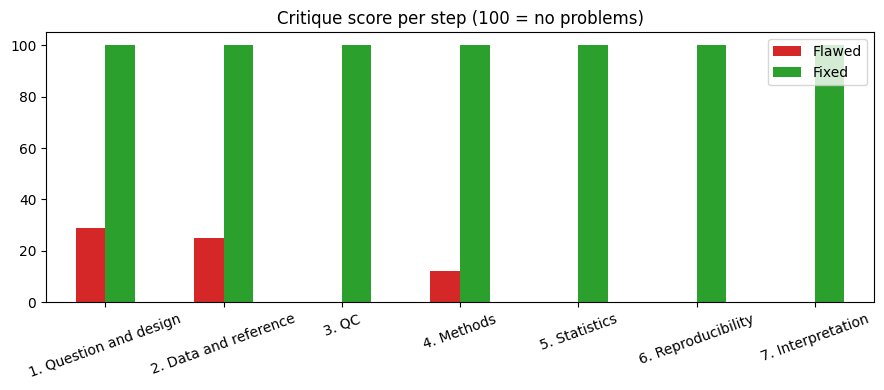


MY THINK-ALOUD ANSWER (say it in this order, about 1.5 minutes)

GOOD FIRST: "STAR with featureCounts is a standard choice, and there are 3 replicates per group."

THEN THE 7 STEPS:
1. Design: all Disease samples are in one batch and all Healthy in another. Batch and
   condition are mixed up, so no method can separate them. This is the biggest problem.
2. Reference: the genome is hg19 but the annotation is GRCh38. Gene counts will be wrong.
3. QC: there is no FastQC, PCA, or outlier check, so the batch problem stayed hidden.
4. Methods: TPM was used for testing between groups. I would use raw counts with DESeq2 or edgeR.
5. Statistics: raw p < 0.05 on thousands of genes gives many false hits. I would use FDR and
   put batch in the model.
6. Reproducibility: no workflow tool, versions, or seed saved. I would use Nextflow, Docker, and Git.
7. Interpretation: "proves the drug cures the disease" is too strong. I would say "associated with"
   and validate top genes by qPCR.

FIX ORDER: 

In [ ]:

# Cell 6: Compare flawed vs fixed pipeline and print the interview script

res_fixed, score_fixed = run_critique(fixed_pipeline)
sc_bad = step_scores(results)
sc_fix = step_scores(res_fixed)

compare = pd.DataFrame({"Flawed": sc_bad, "Fixed": sc_fix})
print(compare)
print(f"\nOverall: flawed {score}/100  ->  fixed {score_fixed}/100")
print("Problems left in fixed pipeline:", [r["name"] for r in res_fixed if not r["ok"]] or "none")

compare.plot(kind="bar", figsize=(9, 4), ylim=(0, 105), color=["tab:red", "tab:green"], rot=20)
plt.title("Critique score per step (100 = no problems)")
plt.tight_layout(); plt.show()

print("\n" + "=" * 66)
print("MY THINK-ALOUD ANSWER (say it in this order, about 1.5 minutes)")
print("=" * 66)
print("""
GOOD FIRST: "STAR with featureCounts is a standard choice, and there are 3 replicates per group."

THEN THE 7 STEPS:
1. Design: all Disease samples are in one batch and all Healthy in another. Batch and
   condition are mixed up, so no method can separate them. This is the biggest problem.
2. Reference: the genome is hg19 but the annotation is GRCh38. Gene counts will be wrong.
3. QC: there is no FastQC, PCA, or outlier check, so the batch problem stayed hidden.
4. Methods: TPM was used for testing between groups. I would use raw counts with DESeq2 or edgeR.
5. Statistics: raw p < 0.05 on thousands of genes gives many false hits. I would use FDR and
   put batch in the model.
6. Reproducibility: no workflow tool, versions, or seed saved. I would use Nextflow, Docker, and Git.
7. Interpretation: "proves the drug cures the disease" is too strong. I would say "associated with"
   and validate top genes by qPCR.

FIX ORDER: redesign the batches, fix the reference, add QC, use counts + DESeq2 with FDR, then
make the run reproducible, then soften the claim.
""")

print("Environment: python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)
print("Note: Cell 5 uses a simple linear model for speed. On real data, use DESeq2/edgeR/limma-voom.")